# Exoplaneten — PCA uitgelegd en toegepast op twaalf SOM-groepen

## Wat hebben we gedaan?
We gebruiken dezelfde 5.481 planeten en tien eigenschappen als in de logaritmische proef. Eerst log10 en dezelfde min-maxschaling; daarna **PCA**; daarna dezelfde SOM met twaalf groepen.

**PCA staat voor Principal Component Analysis: hoofdcomponentenanalyse.** Een hoofdcomponent is een berekende combinatie van de oorspronkelijke eigenschappen. PCA zoekt eerst de richting waarin de planeten het meest van elkaar verschillen; daarna de richting met de grootste resterende spreiding, loodrecht op de eerste; enzovoort. De namen van bekende planeetsoorten of de planeten van ons zonnestelsel zijn daarvoor niet gebruikt.

Denk aan een langwerpige puntenwolk: je beschrijft haar langs haar eigen lengte en breedte, in plaats van langs de oorspronkelijke assen. Iedere planeet krijgt zo nieuwe coördinaten. De coëfficiënten worden uit de exoplanetengegevens berekend; wij hebben niet vooraf bepaald welke verschillen belangrijk moeten zijn.

We bewaren het kleinste aantal hoofdcomponenten dat samen **minstens 95% van de spreiding in de log-geschaalde gegevens** beschrijft. Deze grens is wel een keuze van ons. Ze is niet een grens die de natuur voorschrijft.

## Wat PCA wel en niet doet
- De nieuwe coördinaten zijn in deze dataset onderling **lineair ongecorreleerd**. Dat is niet hetzelfde als volledig statistisch onafhankelijk.
- Samenhangende eigenschappen worden in combinaties ondergebracht. **Dat maakt dubbele informatie niet automatisch onbelangrijk:** eigenschappen die samen variëren kunnen nog steeds veel invloed op de grootste component krijgen.
- Als we alle tien componenten zouden bewaren, blijven de Euclidische afstanden exact gelijk. PCA zou dan alleen de assen draaien en de SOM geen andere afstandsmaat geven. Hier ontstaat de vereenvoudiging doordat we de laatste componenten weglaten.
- We gebruiken geen *whitening*: componenten worden na PCA niet even groot geschaald. Dat zou opnieuw de weging veranderen en kleine richtingen sterker kunnen maken.
- Veel spreiding betekent niet automatisch veel sterrenkundige betekenis. Een zeldzame, belangrijke planeetsoort kan in een richting met weinig spreiding zitten. 95% spreiding behouden is dus niet hetzelfde als 95% van alle kennis behouden.
- Foute of geschatte waarden worden door PCA niet vanzelf hersteld.


## Reproduceerbare vergelijking
De NASA-momentopname, fysieke waarden en rijvolgorde zijn gelijk aan de vorige proef. De SOM houdt 12×1 knopen, 1.600 volledige doorgangen, alpha 0,05 en sigma 4. De oorspronkelijke startgewichten met seed 42 zijn naar de PCA-ruimte geprojecteerd; er is geen andere willekeurige start gekozen.

Na de training wordt de kaart indien nodig als geheel omgedraaid om dezelfde leesrichting als de vorige kaart te krijgen. Dit verandert alleen groepsnummers, geen groepsleden of afstanden. Groepsnummers zijn ook dan geen bewijs dat groepen in twee versies precies dezelfde inhoud hebben.

Pak de volledige map uit. Installeer zo nodig `pip install -r requirements.txt` en open dit notebook in de map met `analysis.py`, `log_som.py` en `pca_som.py`. De bewaarde data worden gebruikt; er is geen nieuwe download nodig.

In [1]:
import json,contextlib,io
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
import pca_som
from analysis import ROOT,FEATURES,LABELS
with contextlib.redirect_stdout(io.StringIO()):
    result=pca_som.run()
assert result['n']==5481 and result['occupied_groups']==12
k=result['retained_components']
display(Markdown(f"**{result['n']:,} planeten, {k} hoofdcomponenten, twaalf groepen.** Samen behouden de componenten **{result['retained_variance']:.2%}** van de spreiding. De rest ({1-result['retained_variance']:.2%}) is weggelaten."))

**5,481 planeten, 4 hoofdcomponenten, twaalf groepen.** Samen behouden de componenten **97.69%** van de spreiding. De rest (2.31%) is weggelaten.

## Hoeveel componenten zijn nodig?
De blauwe balken zijn de bewaarde componenten; grijs is weggelaten. De lijn telt hun verklaarde spreiding op. Onderaan staan de coëfficiënten waarmee de oorspronkelijke log/min-maxgeschaalde kenmerken in de componenten terechtkomen.

Een positief getal betekent: dit kenmerk draagt bij aan een hogere componentscore. Een negatief getal draagt bij aan een lagere score. Het teken van een volledige component is willekeurig: omkeren verandert de informatie niet. Coëfficiënten zijn geen oorzakelijke effecten en zijn hier ook niet hetzelfde als correlaties met de ruwe fysieke waarden.

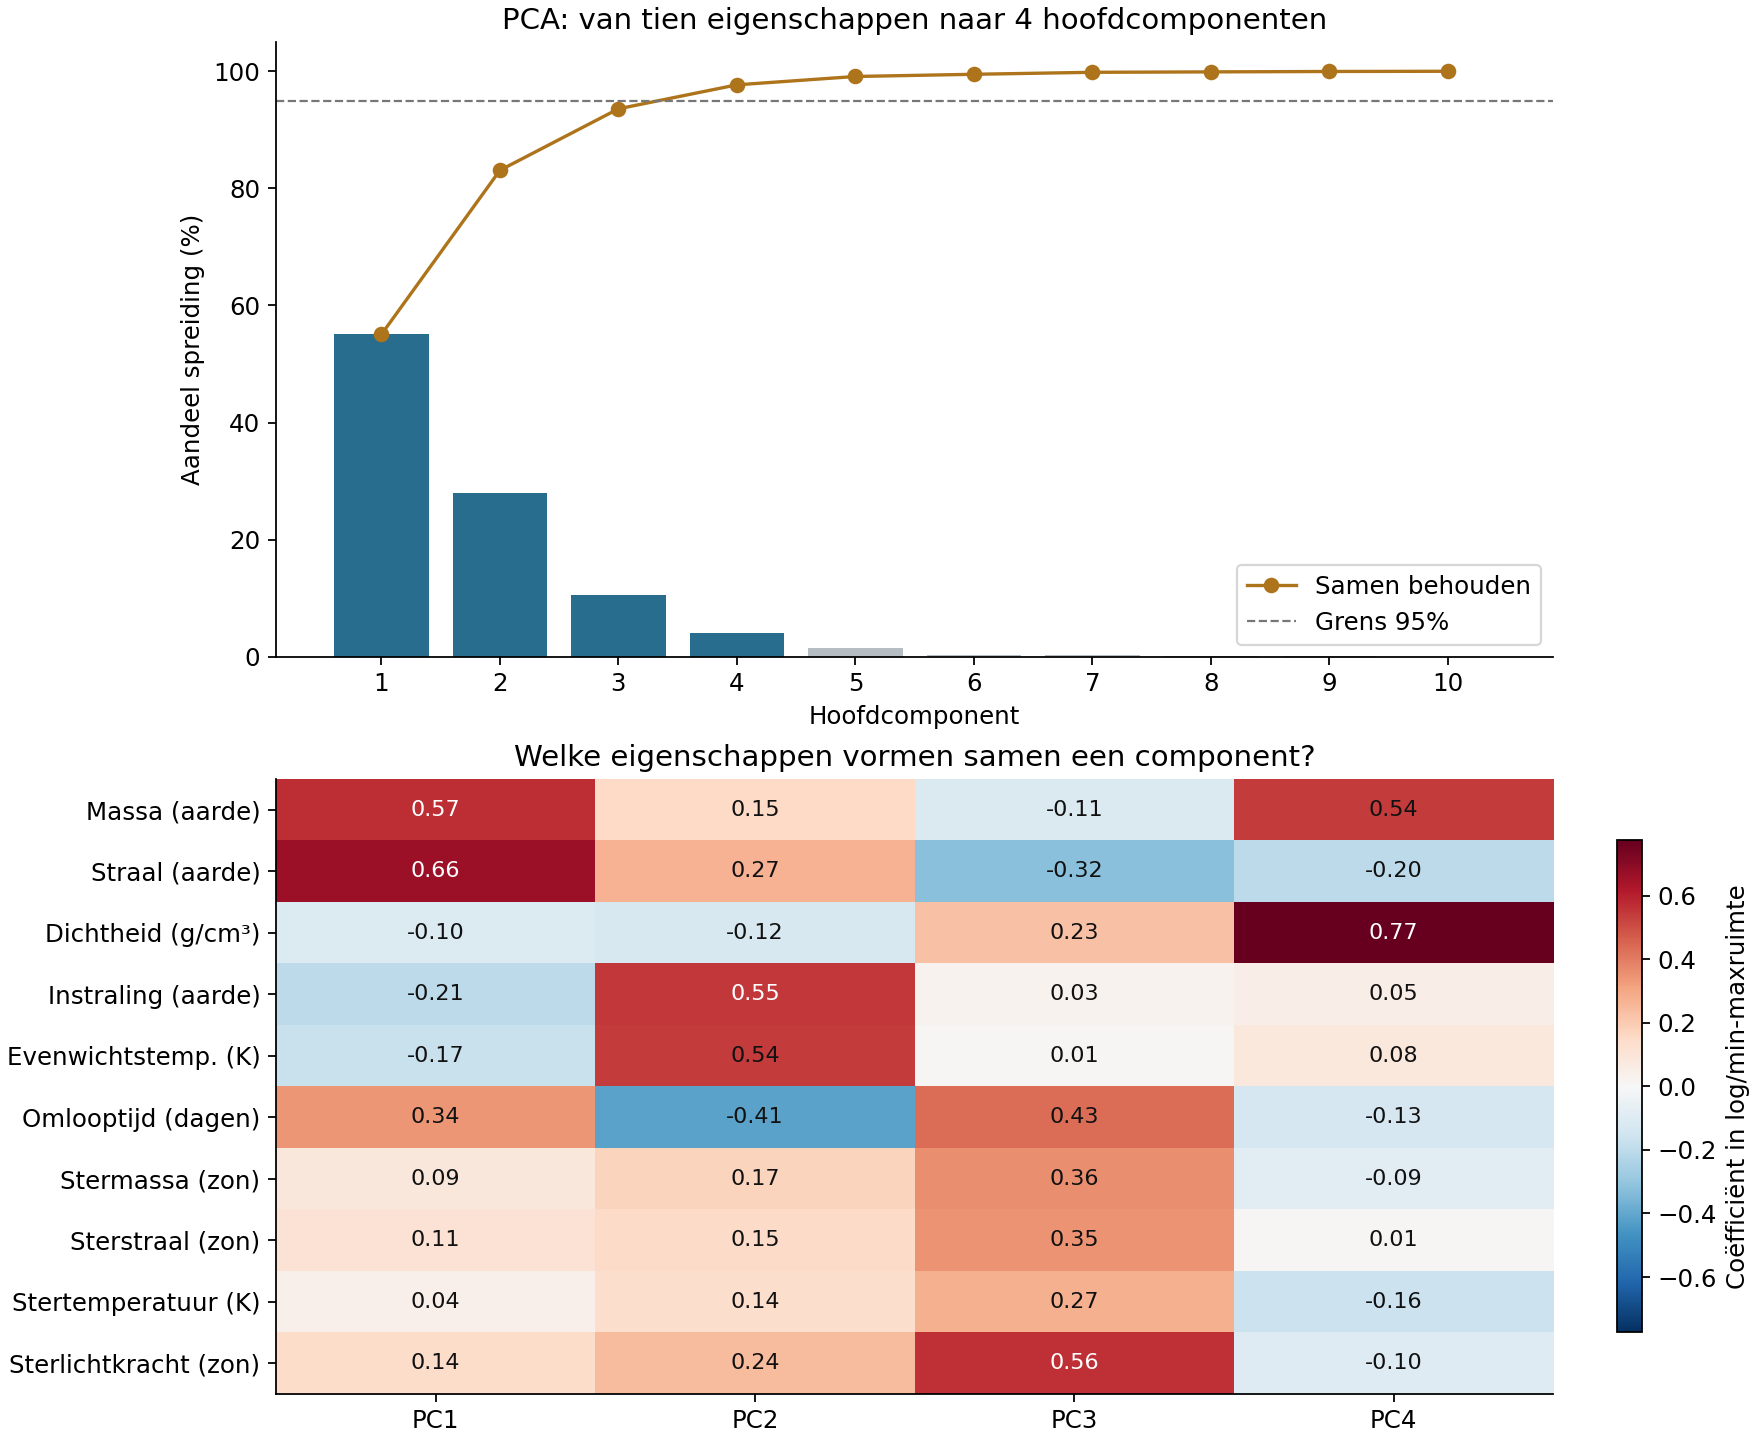

In [2]:
display(Image(filename=str(ROOT/'results_pca/pca_uitleg.png')))

In [3]:
variance=pd.read_csv(ROOT/'results_pca/pca_spreiding.csv')
display(variance.assign(verklaarde_spreiding_pct=variance.verklaarde_spreiding*100,cumulatief_pct=variance.cumulatief*100)[['component','verklaarde_spreiding_pct','cumulatief_pct','bewaard']].round(3))

,component,verklaarde_spreiding_pct,cumulatief_pct,bewaard
0,PC1,55.060,55.060,True
1,PC2,28.029,83.089,True
2,PC3,10.501,93.590,True
3,PC4,4.097,97.687,True
4,PC5,1.424,99.110,False
5,PC6,0.376,99.486,False
6,PC7,0.339,99.825,False
7,PC8,0.071,99.896,False
8,PC9,0.068,99.965,False
9,PC10,0.035,100.000,False


## Wat betekenen de vier componenten ongeveer?
Dit zijn **beschrijvingen achteraf**, op grond van de berekende coëfficiënten, geen vooraf ingestelde categorieën.

| Component | Aandeel spreiding | Grootste bijdragen; globale interpretatie |
|---|---:|---|
| PC1 | 55,1% | Vooral straal en massa; ook omlooptijd. Een combinatie van planeetgrootte, massa en baan. |
| PC2 | 28,0% | Vooral instraling en evenwichtstemperatuur, tegenover omlooptijd. Een combinatie van bestraling en baan. |
| PC3 | 10,5% | Vooral sterlichtkracht en omlooptijd; daarnaast andere sterkenmerken. Een combinatie van steromgeving en baan. |
| PC4 | 4,1% | Vooral dichtheid en massa. Een combinatie die onder meer compacte/zware en ijlere planeten onderscheidt. |

De componenten zijn mengvormen. PC1 is bijvoorbeeld geen zuivere 'grootte-as'. Massa, straal, instraling en temperatuur zijn deels afgeleid of geschat; hun invloed verdwijnt door PCA niet.

In [4]:
coeff=pd.read_csv(ROOT/'results_pca/pca_coefficienten.csv',index_col=0).iloc[:,:k]
coeff.index=LABELS
display(coeff.round(3))

,PC1,PC2,PC3,PC4
Massa (aarde),0.570,0.154,-0.110,0.540
Straal (aarde),0.660,0.266,-0.323,-0.201
Dichtheid (g/cm³),-0.104,-0.121,0.227,0.774
Instraling (aarde),-0.205,0.549,0.027,0.051
Evenwichtstemp. (K),-0.175,0.538,0.011,0.080
Omlooptijd (dagen),0.339,-0.413,0.432,-0.127
Stermassa (zon),0.089,0.174,0.362,-0.090
Sterstraal (zon),0.111,0.147,0.348,0.011
Stertemperatuur (K),0.040,0.135,0.272,-0.164
Sterlichtkracht (zon),0.139,0.243,0.564,-0.097


## De twaalf groepen na PCA
De groepsprofielen worden weer in de oorspronkelijke fysieke eigenschappen beschreven. Je hoeft dus niet in PCA-coördinaten te denken om de gevonden soorten te bestuderen. De kleuren in de onderste figuur zijn mediane percentielrangen binnen de gebruikte exoplaneten, niet de componentcoëfficiënten.

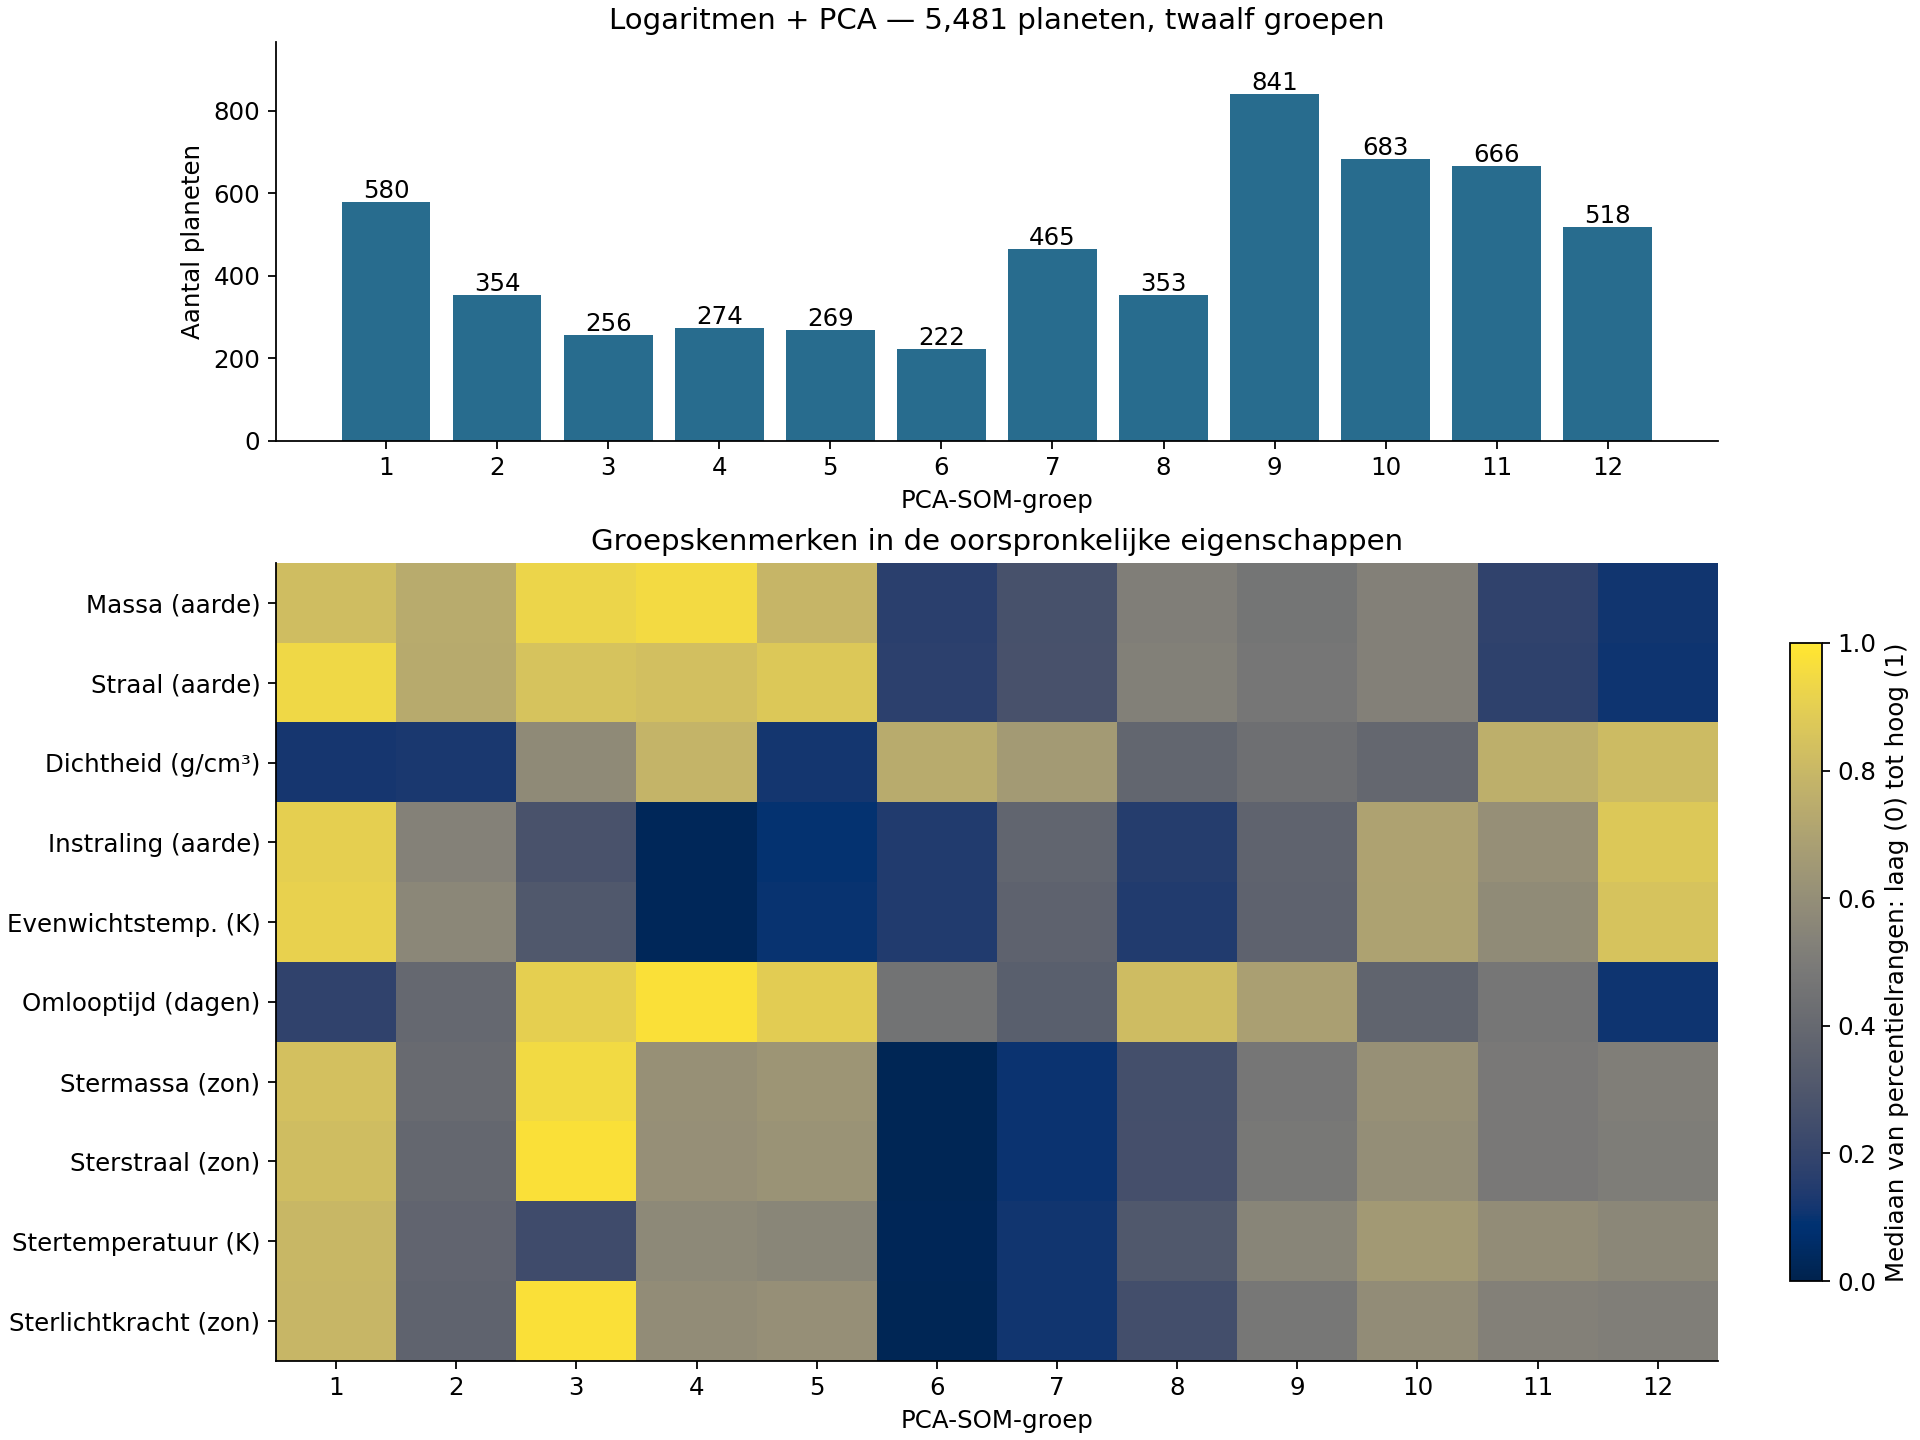

In [5]:
display(Image(filename=str(ROOT/'results_pca/som_pca_overzicht.png')))

In [6]:
profiles=pd.read_csv(ROOT/'results_pca/groepsprofielen_pca.csv').rename(columns=dict(zip(FEATURES,LABELS)))
display(profiles.round(3))

,SOM_groep,aantal,Massa (aarde),Straal (aarde),Dichtheid (g/cm³),Instraling (aarde),Evenwichtstemp. (K),Omlooptijd (dagen),Stermassa (zon),Sterstraal (zon),Stertemperatuur (K),Sterlichtkracht (zon)
0,1,580,319.412,14.100,0.591,946.675,1554.000,3.538,1.195,1.420,5990.0,2.455
1,2,354,114.097,10.560,0.631,85.058,832.000,7.099,0.908,0.880,5295.0,0.547
2,3,256,1109.221,13.000,2.925,15.104,548.785,454.905,1.435,6.475,4880.5,22.505
3,4,274,1829.579,12.800,4.740,0.054,143.885,3550.500,1.020,1.065,5670.5,1.181
4,5,269,216.124,13.300,0.566,1.254,294.420,345.720,1.030,1.079,5645.0,1.249
5,6,222,2.965,1.530,4.350,3.354,361.200,9.027,0.292,0.302,3342.0,0.011
6,7,465,4.420,1.920,3.560,33.463,615.000,5.913,0.607,0.580,4098.0,0.099
7,8,353,8.960,2.910,1.990,3.853,362.000,80.872,0.810,0.781,5103.0,0.350
8,9,841,7.750,2.670,2.210,31.519,614.000,24.368,0.942,0.949,5642.0,0.800
9,10,683,9.360,2.916,2.030,216.900,1007.530,6.581,1.020,1.058,5773.0,1.185


## Ons zonnestelsel als herkenningspunten
De acht planeten worden **achteraf** door dezelfde logschaling en PCA-projectie gehaald en aan de dichtstbijzijnde SOM-knoop toegewezen. Ze hebben de componenten en groepen niet helpen bepalen. Dezelfde NASA-invoer en dezelfde berekende evenwichtstemperaturen als eerder zijn gebruikt.

Een groepsnummer is een beste beschikbare overeenkomst. De afstandspercentielkolom geeft aan welk aandeel van de trainingsplaneten dichter bij zijn eigen knoop ligt dan deze zonnestelselplaneet bij zijn beste knoop. Een hoge waarde, bijvoorbeeld 99%, betekent dus dat deze planeet relatief slecht past. Dit is geen kans op een fout en geen groepskans.

De projectie kan bovendien een deel van de bijzondere eigenschappen van een nieuwe planeet weglaten. Het reconstructieverlies is daarom in de volledige CSV bewaard.

In [7]:
solar=pd.read_csv(ROOT/'results_pca/zonnestelsel_pca.csv')
view=solar[['planeet','log_groep','pca_groep','tweede_pca_groep','afstand_pca','percentiel_afstand_binnen_trainingsset']].copy()
view['percentiel_afstand_binnen_trainingsset']*=100
display(view.round(3))

,planeet,log_groep,pca_groep,tweede_pca_groep,afstand_pca,percentiel_afstand_binnen_trainingsset
0,Mercurius,11,11,12,0.521,99.745
1,Venus,8,8,11,0.368,98.449
2,Aarde,8,8,9,0.366,98.376
3,Mars,8,8,11,0.592,99.836
4,Jupiter,4,4,5,0.172,71.575
5,Saturnus,4,4,5,0.313,96.880
6,Uranus,4,4,5,0.543,99.781
7,Neptunus,4,4,5,0.576,99.818


## Hoeveel verandert de indeling?
De Adjusted Rand Index (ARI) vergelijkt wie met wie in een groep zit, ongeacht de groepsnummers. ARI 1 betekent dezelfde indeling; rond 0 betekent kansniveau. Een ARI van 0,88 betekent niet dat precies 88% van de planeten in dezelfde groep zit.

In [8]:
previous=json.loads((ROOT/'results_log/samenvatting_log.json').read_text())
display(Markdown(f"Overeenkomst met de logaritmische indeling: **ARI {result['adjusted_rand_vs_log']:.3f}**. De topografische fout is **{result['topographic_error']:.2%}**, tegenover **{previous['topographic_error']:.2%}** zonder PCA. Bij die fractie zijn de twee best passende SOM-knopen geen buren. Dit meet hoe goed de lijnvormige kaart de gegevens ordent; het bewijst geen sterrenkundige betekenis."))

Overeenkomst met de logaritmische indeling: **ARI 0.881**. De topografische fout is **28.75%**, tegenover **28.94%** zonder PCA. Bij die fractie zijn de twee best passende SOM-knopen geen buren. Dit meet hoe goed de lijnvormige kaart de gegevens ordent; het bewijst geen sterrenkundige betekenis.

## Wat nemen we mee?
Vier combinaties behouden 97,7% van de spreiding van de tien ingevoerde kenmerken. De indeling blijft grotendeels herkenbaar. De groepjes van ons zonnestelsel blijven hetzelfde: Mercurius apart, Venus/aarde/Mars samen en de vier buitenplaneten samen. Dat is een aanwijzing dat die toewijzingen niet alleen op de laatste, kleine PCA-richtingen berusten.

Verschillende zonnestelselplaneten passen relatief slecht bij hun beste groep. Vooral Jupiter past beter bij de huidige kaart. We moeten de toewijzingen dus niet presenteren alsof iedere planeet een typisch groepslid is.

PCA is een andere beschrijving plus een beperkte vereenvoudiging van de bestaande gegevens. Ze levert **geen volledig onafhankelijke natuurkundige eigenschappen** en maakt onze invoerkeuzes niet neutraal. Deze proef verandert ook niets aan geschatte massa’s, minimum-massa’s, ontdekkingsselectie of de keuze voor twaalf groepen. Een nieuwe stabiliteitsanalyse met meerdere starts is hier niet uitgevoerd.

We kunnen deze twaalf groepen nu inhoudelijk bestuderen; een volgende nieuwe indeling is daarvoor niet nodig.

## Validatie en bronverwijzingen
De code controleert dat dezelfde planeetnamen, rijvolgorde en fysieke waarden worden gebruikt. Zij controleert ook dat de PCA-scores ongecorreleerd zijn, dat alle tien componenten de oorspronkelijke afstanden en oude groepsindeling behouden, en dat opnieuw toewijzen met de bewaarde gewichten exact dezelfde groepen oplevert.

- [PCA in scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [NASA over de exoplanetentabel](https://exoplanetarchive.ipac.caltech.edu/docs/pscp_about.html)
- [NASA Planetary Fact Sheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/)
- [NASA-rekenregels](https://exoplanetarchive.ipac.caltech.edu/docs/pscp_calc.html)

`data/provenance.json` bevat de NASA-query, datum en hash. `results_pca` bevat componentcoëfficiënten, spreiding, groepsprofielen, alle planeettoewijzingen, zonnestelseltoewijzingen, een kruistabel oud/nieuw en het model met alle transformaties. De eerdere resultaten blijven bewaard.
